# EN3150 Assignment 03 — Part 5: Fine-tuning ShuffleNetV2

## 1. Setup
ShuffleNetV2 uses ImageNet normalization for pretrained weights. The same images and train/validation/test split are used as Models A and B. Torchvision automatically downloads the pretrained weights on first use (internet required).

In [1]:
from a03_common import *
from torchvision import models

FREEZE_EPOCHS = 3        # phase 1: train the new head only
FINETUNE_EPOCHS = 12     # phase 2: fine-tune the whole network
HEAD_LR, BACKBONE_LR = 1e-3, 2e-4

set_seed(SEED)
print("Device:", DEVICE)
data = Data(norm="imagenet", batch_size=64, augment=True)
print("Train/Val/Test:", len(data.idx["train"]), len(data.idx["val"]), len(data.idx["test"]))

Device: cpu
Train/Val/Test: 18900 4050 4050


## 2. Model: ShuffleNetV2 (x1.0)
Uses channel splitting, channel shuffling, and depthwise convolutions for efficient inference.
Focuses on real-device speed, considering memory access and hardware limitations alongside MACs.
Replaces the original ImageNet classifier with a 10-class output layer for EuroSAT.

In [2]:
weights = models.ShuffleNet_V2_X1_0_Weights.IMAGENET1K_V1
model = models.shufflenet_v2_x1_0(weights=weights)
model.fc = nn.Linear(model.fc.in_features, data.num_classes)                         # new 10-class head
model = model.to(DEVICE)

total, trainable = count_params(model)
print(f"ShuffleNetV2 x1.0 | total params: {total:,} | trainable: {trainable:,}")
print(model.fc)

Downloading: "https://download.pytorch.org/models/shufflenetv2_x1-5666bf0f80.pth" to C:\Users\Asus/.cache\torch\hub\checkpoints\shufflenetv2_x1-5666bf0f80.pth


100.0%


ShuffleNetV2 x1.0 | total params: 1,263,854 | trainable: 1,263,854
Linear(in_features=1024, out_features=10, bias=True)


## 3. Fine-tuning strategy (two phases)
1. **Phase 1 - head only (3 epochs, Adam lr = 1e-3):** the new classifier layer starts random. Training it alone first stops large random gradients from damaging the good pretrained features.
2. **Phase 2 - whole network (12 epochs, Adam):** unfreeze everything with a **small learning rate for the pretrained backbone (2e-4)** and a larger one for the head (1e-3), so the features adapt gently to satellite images.

In [3]:
HEAD = "fc"

def set_trainable(model, backbone):
    for n, p in model.named_parameters():
        p.requires_grad = n.startswith(HEAD) or backbone

total, _ = count_params(model)

# ---- phase 1: head only ----
set_trainable(model, backbone=False)
_, trainable = count_params(model)
print(f"Phase 1: total params {total:,} | trainable {trainable:,}")
opt1 = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=HEAD_LR)
hist = train_model(model, opt1, data, FREEZE_EPOCHS, name="ShuffleNetV2 phase 1")

# ---- phase 2: whole network ----
set_trainable(model, backbone=True)
_, trainable = count_params(model)
print(f"\nPhase 2: total params {total:,} | trainable {trainable:,}")
backbone = [p for n, p in model.named_parameters() if not n.startswith(HEAD)]
head = [p for n, p in model.named_parameters() if n.startswith(HEAD)]
opt2 = torch.optim.Adam([{"params": backbone, "lr": BACKBONE_LR}, {"params": head, "lr": HEAD_LR}])
hist = train_model(model, opt2, data, FINETUNE_EPOCHS, name="ShuffleNetV2 phase 2", hist=hist)

Phase 1: total params 1,263,854 | trainable 10,250
[ShuffleNetV2 phase 1] epoch 01 | train loss 1.7712 acc 0.6842 | val loss 1.4532 acc 0.7946 | 15.4s
[ShuffleNetV2 phase 1] epoch 02 | train loss 1.2389 acc 0.8043 | val loss 1.1062 acc 0.8156 | 15.9s
[ShuffleNetV2 phase 1] epoch 03 | train loss 0.9871 acc 0.8241 | val loss 0.9244 acc 0.8225 | 15.9s
[ShuffleNetV2 phase 1] best validation accuracy 0.8225 | mean time/epoch (this call) 15.7s

Phase 2: total params 1,263,854 | trainable 1,263,854
[ShuffleNetV2 phase 2] epoch 04 | train loss 0.2924 acc 0.9160 | val loss 0.1514 acc 0.9464 | 72.2s
[ShuffleNetV2 phase 2] epoch 05 | train loss 0.1530 acc 0.9490 | val loss 0.1162 acc 0.9612 | 74.0s
[ShuffleNetV2 phase 2] epoch 06 | train loss 0.1192 acc 0.9597 | val loss 0.1052 acc 0.9649 | 96.1s
[ShuffleNetV2 phase 2] epoch 07 | train loss 0.0896 acc 0.9706 | val loss 0.0895 acc 0.9691 | 90.2s
[ShuffleNetV2 phase 2] epoch 08 | train loss 0.0751 acc 0.9738 | val loss 0.0858 acc 0.9704 | 94.8s
[Sh

## 4. Learning curves
The dashed line marks the end of phase 1. A visible drop in validation loss right after it is the benefit of unfreezing the backbone.

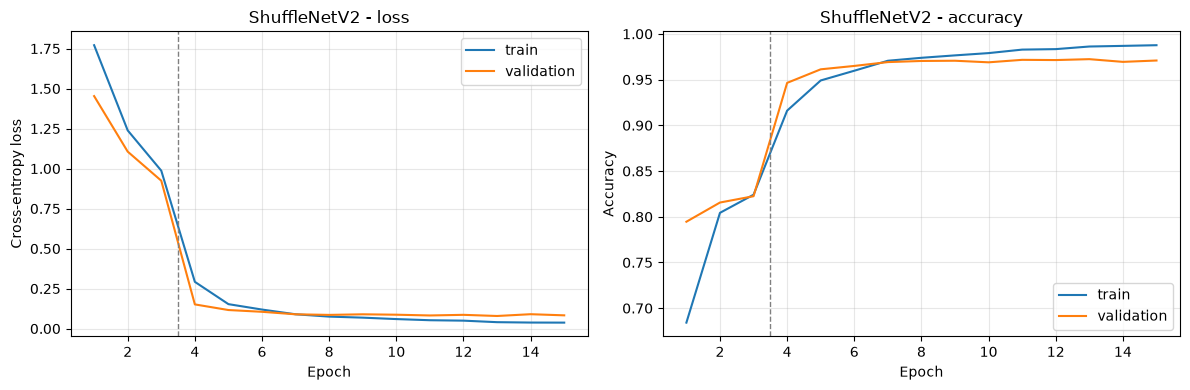

In [4]:
plot_history(hist, "ShuffleNetV2", "shufflenetv2_curves.png", marks=[FREEZE_EPOCHS])

## 5. Test-set evaluation

Test accuracy: 0.9748
Macro precision: 0.9746 | Macro recall: 0.9735 | Macro F1: 0.9740

                      precision    recall  f1-score   support

          AnnualCrop     0.9583    0.9711    0.9647       450
              Forest     0.9912    0.9978    0.9945       450
HerbaceousVegetation     0.9620    0.9556    0.9588       450
             Highway     0.9534    0.9813    0.9671       375
          Industrial     0.9892    0.9733    0.9812       375
             Pasture     0.9793    0.9467    0.9627       300
       PermanentCrop     0.9439    0.9413    0.9426       375
         Residential     0.9846    0.9933    0.9889       450
               River     0.9840    0.9813    0.9826       375
             SeaLake     1.0000    0.9933    0.9967       450

            accuracy                         0.9748      4050
           macro avg     0.9746    0.9735    0.9740      4050
        weighted avg     0.9749    0.9748    0.9748      4050



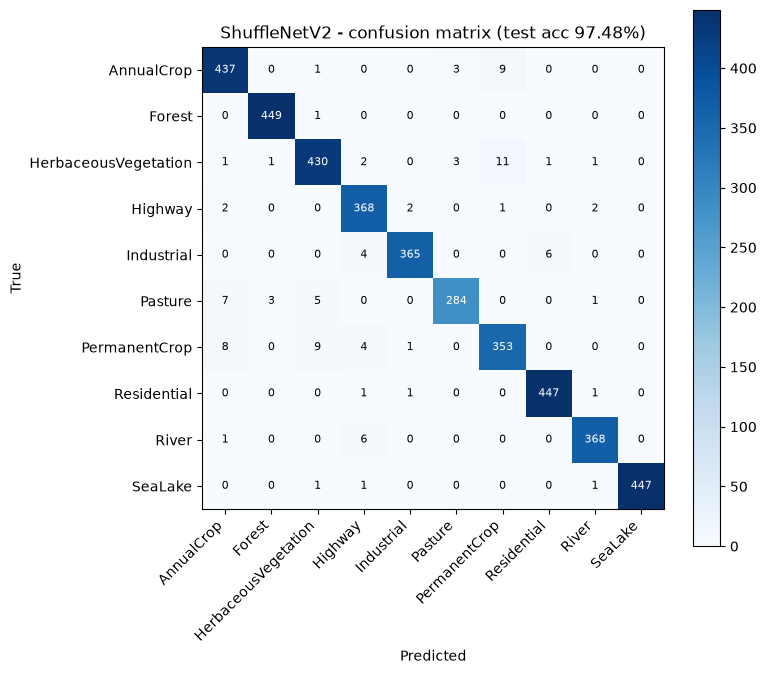

Most confused pairs (true -> predicted : count)
  HerbaceousVegetation -> PermanentCrop : 11
  PermanentCrop -> HerbaceousVegetation : 9
  AnnualCrop -> PermanentCrop : 9
  PermanentCrop -> AnnualCrop : 8
  Pasture -> AnnualCrop : 7


In [5]:
ev = evaluate(model, data)
cm = plot_confusion(ev["y_true"], ev["y_pred"], data.classes,
                    f"ShuffleNetV2 - confusion matrix (test acc {ev['acc']:.2%})", "shufflenetv2_confusion.png")

## 6. Parameter count, model size (MB) and cost metrics
Model size is the float32 `state_dict` on disk. **Time per epoch** is reported for phase 2 (full backpropagation through the whole network), the figure comparable with the custom models. Everything goes to the results JSON used by the final comparison notebook.

In [6]:
total, trainable = count_params(model)
ft_time = float(np.mean(hist["epoch_time"][FREEZE_EPOCHS:]))
res = save_results("shufflenetv2", "ShuffleNetV2 (fine-tuned)", model, hist, ev,
                   "Adam, 2-phase fine-tuning", data, time_per_epoch_s=ft_time,
                   extra={"time_per_epoch_phase1_s": float(np.mean(hist["epoch_time"][:FREEZE_EPOCHS]))})
print(f"\nTotal parameters: {total:,} | Model size: {res['size_kb']/1024:.2f} MB")

{
  "model": "ShuffleNetV2 (fine-tuned)",
  "optimizer": "Adam, 2-phase fine-tuning",
  "epochs": 15,
  "params": 1263854,
  "trainable_params": 1263854,
  "macs": 11755872,
  "size_kb": 5103.1,
  "time_per_epoch_s": 128.55,
  "latency_ms_cpu": 23.2,
  "best_val_acc": 0.9723456790123457,
  "test_acc": 0.9748148148148148,
  "macro_precision": 0.9745699087850307,
  "macro_recall": 0.9735111111111111,
  "macro_f1": 0.9739764571961425,
  "time_per_epoch_phase1_s": 15.742291371027628
}

Total parameters: 1,263,854 | Model size: 4.98 MB
